In [1]:
import copy
import numpy as np
import pandas as pd
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score, confusion_matrix

In [2]:
NAME_CSV = "solved_09.csv"
TARGET = 'is_fraud'
SEED = 42

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
np.random.seed(SEED)
print('device:', DEVICE)

device: cpu


In [3]:
df_test = pd.read_csv('data/test.csv')
df_train = pd.read_csv('data/train.csv')

In [4]:
def get_ids(df):
    return df['id']

In [5]:
def feature_engenier(df_1, df_2):
    df = pd.concat([df_1, df_2], axis=0).drop(columns='id')

    # Quanto do saldo foi gasto na transacao
    df['proporcao_gasta_na_transacao'] = df['amount_usd'] / df['account_balance_usd']
    # Contestacoes anteriores relativas a idade do cartao
    df['reclamacoes_por_idade'] = df['prior_disputes'] / df['card_age_months'] * 100

    df = df.drop(columns=['amount_usd', 'account_balance_usd', 'card_age_months'])

    # divisoes por zero geram inf, que quebram a rede neural
    df = df.replace([np.inf, -np.inf], np.nan)

    # as duas colunas criadas tem cauda muito pesada: log1p ajuda a rede
    for col in ['proporcao_gasta_na_transacao', 'reclamacoes_por_idade']:
        df[col] = np.log1p(df[col].clip(lower=0))
    return df

In [6]:
def transform_data(df) -> pd.DataFrame:
    targets = df[TARGET].reset_index(drop=True)
    df = df.drop(columns=[TARGET])

    # booleanos viram 0/1 (antes era contagem de frequencia, que dava valores ~1e6)
    boolean_features = list(df.select_dtypes(include='bool').columns)
    df[boolean_features] = df[boolean_features].astype(float)

    string_features = list(df.select_dtypes(['string', 'object']).columns)
    numeric_features = list(df.select_dtypes(['number']).columns)

    # redes neurais nao aceitam NaN
    df[numeric_features] = df[numeric_features].fillna(df[numeric_features].median())

    preprocess = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            ("str", OneHotEncoder(handle_unknown='ignore', sparse_output=False), string_features),
        ],
        remainder='drop',
    )

    values = preprocess.fit_transform(df)
    out = pd.DataFrame(values, columns=preprocess.get_feature_names_out())
    out[TARGET] = targets.values
    return out

In [7]:
n_train = len(df_train)
ids = get_ids(df_test)

df = feature_engenier(df_train, df_test)
df = transform_data(df)

df_train = df.iloc[:n_train]
df_test = df.iloc[n_train:]
print(df_train.shape, df_test.shape)

(699960, 54) (299984, 54)


In [8]:
x = df_train.drop(columns=TARGET)
y = df_train[TARGET]

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, shuffle=True, random_state=SEED, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, shuffle=True, random_state=SEED, stratify=y_temp)
print(x_train.shape, x_val.shape, x_test.shape)

def to_tensor(a):
    return torch.tensor(np.asarray(a, dtype=np.float32))

X_train, X_val, X_test = map(to_tensor, (x_train, x_val, x_test))
Y_train, Y_val, Y_test = map(to_tensor, (y_train, y_val, y_test))

BATCH_SIZE = 2048
train_loader = DataLoader(
    TensorDataset(X_train, Y_train),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
)

(489972, 53) (104994, 53) (104994, 53)


In [9]:
class ResBlock(nn.Module):
    def __init__(self, dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.BatchNorm1d(dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
        )

    def forward(self, x):
        return x + self.net(x)


class FraudNet(nn.Module):
    """MLP residual para dados tabulares. Retorna logits."""
    def __init__(self, in_dim, hidden=256, n_blocks=3, dropout=0.2):
        super().__init__()
        self.inp = nn.Linear(in_dim, hidden)
        self.blocks = nn.Sequential(*[ResBlock(hidden, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(
            nn.BatchNorm1d(hidden),
            nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.head(self.blocks(self.inp(x))).squeeze(1)


model = FraudNet(in_dim=X_train.shape[1]).to(DEVICE)
print(model)
print('parametros:', sum(p.numel() for p in model.parameters()))

FraudNet(
  (inp): Linear(in_features=53, out_features=256, bias=True)
  (blocks): Sequential(
    (0): ResBlock(
      (net): Sequential(
        (0): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (1): SiLU()
        (2): Dropout(p=0.2, inplace=False)
        (3): Linear(in_features=256, out_features=256, bias=True)
      )
    )
    (1): ResBlock(
      (net): Sequential(
        (0): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (1): SiLU()
        (2): Dropout(p=0.2, inplace=False)
        (3): Linear(in_features=256, out_features=256, bias=True)
      )
    )
    (2): ResBlock(
      (net): Sequential(
        (0): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (1): SiLU()
        (2): Dropout(p=0.2, inplace=False)
        (3): Linear(in_features=256, out_features=256, bias=True)
      )
    )
  )
  (head): Sequential(
   

In [10]:
@torch.no_grad()
def predict_proba(model, X, bs=8192):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        out.append(torch.sigmoid(model(X[i:i + bs].to(DEVICE))).cpu())
    return torch.cat(out).numpy()

In [11]:
EPOCHS = 40
MAX_LR = 2e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 8

use_amp = DEVICE.type == 'cuda'
criterion = nn.BCEWithLogitsLoss()  # a metrica e AUC, entao nao precisa de pos_weight
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=MAX_LR, epochs=EPOCHS, steps_per_epoch=len(train_loader)
)
grad_scaler = torch.amp.GradScaler(enabled=use_amp)

best_auc, best_state, bad_epochs = 0.0, None, 0

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            loss = criterion(model(xb), yb)
        grad_scaler.scale(loss).backward()
        grad_scaler.step(optimizer)
        grad_scaler.update()
        scheduler.step()
        total_loss += loss.item()

    val_auc = roc_auc_score(y_val, predict_proba(model, X_val))
    print(f"[{epoch:02d}] loss={total_loss / len(train_loader):.4f}  val_auc={val_auc:.5f}")

    if val_auc > best_auc:
        best_auc, best_state, bad_epochs = val_auc, copy.deepcopy(model.state_dict()), 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print('early stopping')
            break

model.load_state_dict(best_state)
print('melhor val_auc:', best_auc)

[00] loss=0.4375  val_auc=0.89879
[01] loss=0.1819  val_auc=0.92026
[02] loss=0.0848  val_auc=0.92679
[03] loss=0.0568  val_auc=0.93482
[04] loss=0.0503  val_auc=0.93798
[05] loss=0.0484  val_auc=0.93543
[06] loss=0.0476  val_auc=0.93890
[07] loss=0.0474  val_auc=0.93610
[08] loss=0.0472  val_auc=0.93916
[09] loss=0.0469  val_auc=0.93608
[10] loss=0.0466  val_auc=0.93763
[11] loss=0.0464  val_auc=0.93813
[12] loss=0.0463  val_auc=0.93713
[13] loss=0.0461  val_auc=0.93640
[14] loss=0.0459  val_auc=0.93560
[15] loss=0.0456  val_auc=0.93502
[16] loss=0.0456  val_auc=0.93642
early stopping
melhor val_auc: 0.9391621884245762


test AUC: 0.9396351829891451


<Axes: >

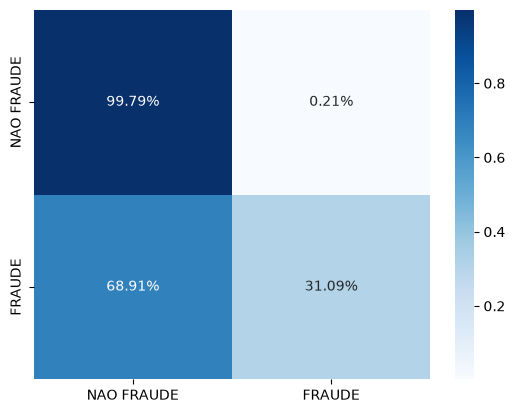

In [12]:
p_test = predict_proba(model, X_test)
print('test AUC:', roc_auc_score(y_test, p_test))

cm = confusion_matrix(y_test, (p_test >= 0.5).astype(int), normalize='true')
sns.heatmap(
    cm,
    cmap='Blues',
    fmt='.2%',
    annot=True,
    xticklabels=["NAO FRAUDE", "FRAUDE"],
    yticklabels=["NAO FRAUDE", "FRAUDE"],
)

In [13]:
X_final = to_tensor(df_test.drop(columns=TARGET))
out = predict_proba(model, X_final)

df_final = pd.DataFrame({"id": ids.values, "is_fraud": out})
df_final.to_csv(NAME_CSV, index=False)
df_final.head()

,id,is_fraud
0,699960,0.000194
1,699961,0.000183
2,699962,0.114237
3,699963,0.002237
4,699964,0.001599
